# Minimal Type I seesaw content compatible with current neutrino data

What is the smallest number of active ($n$) and sterile ($m$) neutrinos for which the Type I seesaw

$$\mathcal M=\begin{pmatrix}0 & m_D\\ m_D^T & M_R\end{pmatrix},\qquad W^T\mathcal M W=\mathrm{diag}(m_1,\dots,m_{n+m}),\ m_i\ge0,$$

reproduces the oscillation data of **NuFIT 6.0** (Esteban *et al.*, JHEP 12 (2024) 216, arXiv:2410.05380)?

**Assumptions**

* Type I seesaw only, tree level, three charged leptons. $M_R$ is diagonal and positive, which is always achievable by a sterile-basis rotation.
* Light masses in eV, heavy masses and $m_D$ in GeV.
* Takagi convention $W^TMW=\mathrm{diag}(m\ge0)$ as in `src.symbolic_diagonalization`. The active–light block $N$ of $W$ is the (non-unitary) PMNS matrix, $N=(1-\eta)U$ with $U$ unitary.
* The NuFIT $\Delta\chi^2$ profiles are approximated by Gaussians with asymmetric errors. This is crude for $\delta_{CP}$ and the $\theta_{23}$ octant, but sufficient to separate viable from excluded field contents.

**Result** (derived below): $n=3$ and $m=2$, i.e. **(3, 2)**, is the minimal content. It predicts $m_{\rm lightest}=0$. In normal ordering it is fully compatible with the data. In inverted ordering it is compatible with oscillations, but in tension with the cosmological bound on $\sum m_\nu$.

In [1]:
import os
import sys

project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

import numpy as np
import matplotlib.pyplot as plt

from src.pmns_matrix import nufit_6_0
from src.seesaw import SymbolicSeesawTypeI
from src.data_fit import (GEV, rank_argument, fit_case, chi2, chi2_contributions,
                          minimal_model, exact_light_observables,
                          majorana_effective_mass_range)

%matplotlib inline
np.set_printoptions(precision=5, suppress=False, linewidth=110)

Missing colon in file PosixPath('/home/moises/.config/matplotlib/stylelib/ifunam.mplstyle'), line 28 ("    '003DA5',")


Missing colon in file PosixPath('/home/moises/.config/matplotlib/stylelib/ifunam.mplstyle'), line 29 ("    'C0392B',")


Missing colon in file PosixPath('/home/moises/.config/matplotlib/stylelib/ifunam.mplstyle'), line 30 ("    '1A6B3A',")


Missing colon in file PosixPath('/home/moises/.config/matplotlib/stylelib/ifunam.mplstyle'), line 31 ("    'FFBE00',")


Missing colon in file PosixPath('/home/moises/.config/matplotlib/stylelib/ifunam.mplstyle'), line 32 ("    '3F6FD1',")


Missing colon in file PosixPath('/home/moises/.config/matplotlib/stylelib/ifunam.mplstyle'), line 33 ("    '8E44AD',")


... (3 outputs left out)

Missing colon in file PosixPath('/home/moises/.config/matplotlib/stylelib/ifunam.mplstyle'), line 37 ("    'CB4335'])")


Bad value in file PosixPath('/home/moises/.config/matplotlib/stylelib/ifunam.mplstyle'), line 21 ('axes.edgecolor    : #4A4A6A'): Key axes.edgecolor: '' does not look like a color arg


Bad value in file PosixPath('/home/moises/.config/matplotlib/stylelib/ifunam.mplstyle'), line 27 ("axes.prop_cycle : cycler('color', ["): Key axes.prop_cycle: "cycler('color', [" is not a valid cycler construction: '[' was never closed (<unknown>, line 1)


Bad value in file PosixPath('/home/moises/.config/matplotlib/stylelib/ifunam.mplstyle'), line 95 ('patch.edgecolor       : face'): Key patch.edgecolor: 'face' does not look like a color arg


## 1. Data: NuFIT 6.0

Two variants: with the Super-Kamiokande atmospheric $\chi^2$ table (IC24 + SK-atm, normal ordering preferred by $\Delta\chi^2=6.1$) and without it (IC19, inverted ordering marginally preferred by $\Delta\chi^2=0.6$). $\Delta m^2_{3\ell}=\Delta m^2_{31}>0$ for NO and $\Delta m^2_{32}<0$ for IO.

In [2]:
variants = {'with_sk': nufit_6_0('with_sk'), 'without_sk': nufit_6_0('without_sk')}
keys = ['sin2_theta12', 'sin2_theta13', 'sin2_theta23', 'delta_cp_deg', 'dm21_sq', 'dm3l_sq']
print(f"{'':14s}" + ''.join(f"{v + (' NO' if o == 'normal' else ' IO'):>22s}" for v in variants for o in ('normal', 'inverted')))
for k in keys:
    row = f"{k:14s}"
    for data in variants.values():
        for o in ('normal', 'inverted'):
            b, up, dn = data[o][k][:3]
            row += f"{b:>12.5g} +{up:.2g}/-{dn:.2g}"
    print(row)
print(f"{'delta_chi2':14s}" + ''.join(f"{variants[v][o]['delta_chi2']:>22.1f}" for v in variants for o in ('normal', 'inverted')))

                          with_sk NO            with_sk IO         without_sk NO         without_sk IO
sin2_theta12         0.308 +0.012/-0.011       0.308 +0.012/-0.011       0.307 +0.012/-0.011       0.308 +0.012/-0.011
sin2_theta13       0.02215 +0.00056/-0.00058     0.02231 +0.00056/-0.00056     0.02195 +0.00054/-0.00058     0.02224 +0.00056/-0.00057
sin2_theta23          0.47 +0.017/-0.013        0.55 +0.012/-0.015       0.561 +0.012/-0.015       0.562 +0.012/-0.015
delta_cp_deg           212 +26/-41         274 +22/-25         177 +19/-20         285 +25/-28
dm21_sq           7.49e-05 +1.9e-06/-1.9e-06    7.49e-05 +1.9e-06/-1.9e-06    7.49e-05 +1.9e-06/-1.9e-06    7.49e-05 +1.9e-06/-1.9e-06
dm3l_sq           0.002513 +2.1e-05/-1.9e-05   -0.002484 +2e-05/-2e-05    0.002534 +2.5e-05/-2.3e-05    -0.00251 +2.4e-05/-2.5e-05
delta_chi2                       0.0                   6.1                   0.6                   0.0


## 2. Why $n = 3$

* **Z width.** The invisible width of the $Z$ counts the light active neutrinos: $N_\nu = 2.9963\pm0.0074$ (LEP, with the luminosity correction of Janot & Jadach 2019). Any additional light state must be sterile.
* **Mixing.** All three PMNS angles are measured to be non-zero ($\sin^2\theta_{13}$ at more than $30\sigma$), and oscillations involve $\nu_e,\nu_\mu,\nu_\tau$. A model with $n=2$ has a single angle and no Dirac phase, so it cannot reproduce them.

The cases $(1,m)$ and $(2,m)$ studied in the other notebooks are therefore toy models for the diagonalization, not candidates for the data. From now on $n=3$.

## 3. Structural argument: rank of the light sector

The first $n$ columns of $\mathcal M$ are $(0, m_D^T)^T$, of rank $\le\min(n,m)$, so $\operatorname{rank}\mathcal M\le m+\min(n,m)$. For $n>m$ exactly $n-m$ light states are **massless**, to all orders in $m_D/M_R$ (at tree level). Equivalently, $m_\nu=-m_DM_R^{-1}m_D^T$ has rank $\min(n,m)$.

Oscillations need **two** independent non-zero splittings, $\Delta m^2_{21}\simeq7.5\times10^{-5}$ eV$^2$ and $|\Delta m^2_{3\ell}|\simeq2.5\times10^{-3}$ eV$^2$. This requires at least two massive light states, hence $m\ge2$.

In [3]:
print(f"{'(n, m)':8s} {'rank M':>7s} {'massless':>9s} {'non-zero splittings':>20s}")
for m in (1, 2, 3):
    rank = SymbolicSeesawTypeI(3, m, dirac='generic').full_mass_matrix_symbolic().rank()
    info = rank_argument(3, m)
    assert info['n_massless'] == SymbolicSeesawTypeI(3, m).n_massless == 3 + m - rank
    print(f"{str((3, m)):8s} {rank:>7d} {info['n_massless']:>9d} {info['n_nonzero_splittings']:>20d}")

(n, m)    rank M  massless  non-zero splittings
(3, 1)         2         2                    1


(3, 2)         4         1                    2


(3, 3)         6         0                    2


## 4. Brute-force fits for $(3,1)$, $(3,2)$, $(3,3)$

The low-energy observables depend on $m_D$ and $M_R$ only through $m_\nu=-YY^T$, with $Y=m_DM_R^{-1/2}$ a **generic** complex $3\times m$ matrix. `fit_case` minimizes the $\chi^2$ over all $6m$ real parameters of $Y$ from random starting points. It assumes nothing about the solution (no Casas–Ibarra input) and does not depend on the heavy scale. Corrections beyond $m_\nu=-YY^T$ are of relative size $m_\nu/M_N$; Section 5 checks them exactly.

In [4]:
fits = {}
for variant, data in variants.items():
    for ordering in ('normal', 'inverted'):
        for m in (1, 2, 3):
            fits[variant, ordering, m] = fit_case(m, ordering, data, n_starts=10, seed=1)

print(f"{'variant':11s} {'ordering':9s} " + ''.join(f"{'chi2_min (3,' + str(m) + ')':>17s}" for m in (1, 2, 3)))
for variant in variants:
    for ordering in ('normal', 'inverted'):
        print(f"{variant:11s} {ordering:9s} " + ''.join(f"{fits[variant, ordering, m]['chi2']:>17.3g}" for m in (1, 2, 3)))

variant     ordering     chi2_min (3,1)   chi2_min (3,2)   chi2_min (3,3)
with_sk     normal             1.59e+03         1.03e-16          1.6e-14
with_sk     inverted           1.53e+04          2.4e-15         1.32e-14
without_sk  normal             1.59e+03         2.54e-16         8.71e-15
without_sk  inverted           1.11e+04         2.39e-14         2.97e-14


In [5]:
r = fits['with_sk', 'normal', 1]
print('(3,1), NO: best-fit masses [eV] =', r['observables']['masses'])
print('pulls:', {k: round(v, 1) for k, v in r['pulls'].items()})

(3,1), NO: best-fit masses [eV] = [1.02208e-18 4.20973e-18 5.08250e-02]
pulls: {'dm21_sq': -39.4, 'dm3l_sq': 3.3, 'sin2_theta12': -4.4, 'sin2_theta13': 0.9, 'sin2_theta23': 0.1, 'delta_cp_deg': -2.9}


For $(3,1)$ the minimum puts the single massive state at the atmospheric scale and leaves $\Delta m^2_{21}=0$, a $\approx 39\sigma$ pull in the Gaussian approximation. KamLAND and the solar data exclude $\Delta m^2_{21}=0$ far beyond any reasonable threshold. The angle pulls are irrelevant here, since two degenerate massless states make the mixing in that subspace unphysical. In IO the situation is worse. $(3,2)$ and $(3,3)$ fit the best-fit point exactly ($\chi^2=0$) in both orderings and both variants.

## 5. The minimal model $(3,2)$, constructed explicitly

The exact Casas–Ibarra parametrization (`exact_seesaw_parametrization` in `src.symbolic_diagonalization`, ported numerically in `casas_ibarra_exact_numeric`) gives $m_D$ and $M_R$ from

* the light masses $d=(0,m_a,m_b)$, fixed by the data: NO $(m_1,m_2,m_3)=(0,\sqrt{\Delta m^2_{21}},\sqrt{\Delta m^2_{31}})$, IO $(m_1,m_2,m_3)=(\sqrt{|\Delta m^2_{32}|-\Delta m^2_{21}},\sqrt{|\Delta m^2_{32}|},0)$;
* the PMNS matrix, including one Majorana phase $\alpha$;
* free high-energy parameters: the heavy masses $M_{1,2}$ and one complex angle $z$ ($O\in O(2,\mathbb C)$ on the massive states).

The low-energy content of $(3,2)$ is $2$ masses, $3$ angles, $\delta$ and $\alpha$: 7 parameters, all except $\alpha$ measured.

Then the full $5\times5$ matrix is diagonalized **without any expansion**, in 80-digit arithmetic (`exact_light_observables`). The light/heavy hierarchy $M_N/m_\nu\sim10^{24}$ is far beyond double precision.

In [6]:
data = variants['with_sk']
for ordering in ('normal', 'inverted'):
    model = minimal_model(ordering, data, z=0.4 + 0.3j, majorana_phase=1.0,
                          heavy_masses_gev=(1e13, 1e14))
    exact = exact_light_observables(model['M_ev'], 3, ordering, dps=80)
    W, M = model['W'], model['M_ev']
    residual = np.max(np.abs(W.T @ M @ W - np.diag(np.r_[model['light_masses'], model['heavy_masses_gev'] * GEV])))
    print(f"--- {ordering} ordering ---")
    print('m_D [GeV] =\n', model['m_D_gev'])
    print('M_R [GeV] =\n', model['M_R_gev'])
    print('|W^T M W - diag| / M_max      =', residual / M.real.max())
    print('light masses, construction   =', model['light_masses'])
    print('light masses, exact 80 digits =', exact['light_masses'])
    print(f"{'':14s}{'NuFIT':>12s}{'exact 5x5':>14s}")
    for k in keys:
        print(f"{k:14s}{data[ordering][k][0]:>12.6g}{exact[k]:>14.6g}")
    print('chi2 (exact) =', chi2(exact, data, ordering))

--- normal ordering ---
m_D [GeV] =
 [[1.37656 +4.67866j 3.49354 -1.32763j]
 [7.91698 -1.54456j 5.14571+55.71453j]
 [2.02176-10.53643j 7.28425+41.61167j]]
M_R [GeV] =
 [[1.00000e+13+4.93628e-35j 1.01458e-11-2.98914e-11j]
 [1.01458e-11-2.98914e-11j 1.00000e+14-5.56749e-36j]]
|W^T M W - diag| / M_max      = 1.1102230246251565e-16
light masses, construction   = [0.      0.00865 0.05013]
light masses, exact 80 digits = [3.43771e-20 8.65448e-03 5.01298e-02]
                     NuFIT     exact 5x5
sin2_theta12         0.308         0.308
sin2_theta13       0.02215       0.02215
sin2_theta23          0.47          0.47
delta_cp_deg           212           212
dm21_sq           7.49e-05      7.49e-05
dm3l_sq           0.002513      0.002513
chi2 (exact) = 6.177629172701919e-26
--- inverted ordering ---
m_D [GeV] =
 [[  2.78557+11.52153j   5.75125+53.98933j]
 [  0.9229 -14.46835j  35.58916+19.36563j]
 [  1.52411+15.18863j -27.30757-23.54954j]]
M_R [GeV] =
 [[ 1.00000e+13+1.51907e-24j -7.04961e

The massless state comes out at $\sim10^{-19}$ eV. This is the precision floor of $\sqrt{\lambda_{\min}(\mathcal M^\dagger\mathcal M)}$ at 80 digits, not a physical mass. The rank argument makes it exactly zero.

The minimal model is also the largest case where the closed-form route of the series still works. $(3,2)$ has $k=4$ massive states, and its reduced characteristic polynomial is a quartic, solved by `direct_diagonalization` in `seesaw_3_active_2_sterile.ipynb`. The realistic minimal seesaw is therefore exactly solvable in radicals, while $(3,3)$ ($k=6$, Galois group $S_6$) is not.

## 6. Predictions of $(3,2)$ and non-oscillation constraints

With $m_{\rm lightest}=0$ the absolute scale is fixed:

* **Cosmology:** DESI DR2 BAO + CMB give $\sum m_\nu<0.064$ eV (95 %, $\Lambda$CDM; arXiv:2503.14738).
* **$\beta$ decay:** KATRIN gives $m_\beta<0.45$ eV (90 %; arXiv:2406.13516).
* **$0\nu\beta\beta$:** KamLAND-Zen gives $m_{\beta\beta}<28$–$122$ meV (90 %, the range from nuclear matrix elements; arXiv:2406.11438).

The cosmological bound depends on the model (for example on dynamical dark energy) and on the prior $\sum m_\nu\ge0$, so the tension below should not be read as an exclusion.

In [7]:
print(f"{'variant':11s} {'ordering':9s} {'sum m [eV]':>11s} {'m_beta [eV]':>12s} {'m_bb range [meV]':>18s}")
mbb = {}
for variant, data in variants.items():
    for ordering in ('normal', 'inverted'):
        obs = minimal_model(ordering, data)['observables']
        mbb[variant, ordering] = majorana_effective_mass_range(ordering, data)
        rng_ = mbb[variant, ordering]
        print(f"{variant:11s} {ordering:9s} {obs['sum_masses']:>11.4f} {obs['m_beta']:>12.4f}"
              f"   {1e3 * rng_['min']:6.2f} - {1e3 * rng_['max']:6.2f}")

variant     ordering   sum m [eV]  m_beta [eV]   m_bb range [meV]


with_sk     normal         0.0588       0.0088     1.50 -   3.72


with_sk     inverted       0.0989       0.0488    18.20 -  48.22


without_sk  normal         0.0590       0.0088     1.49 -   3.70


without_sk  inverted       0.0994       0.0490    18.30 -  48.48


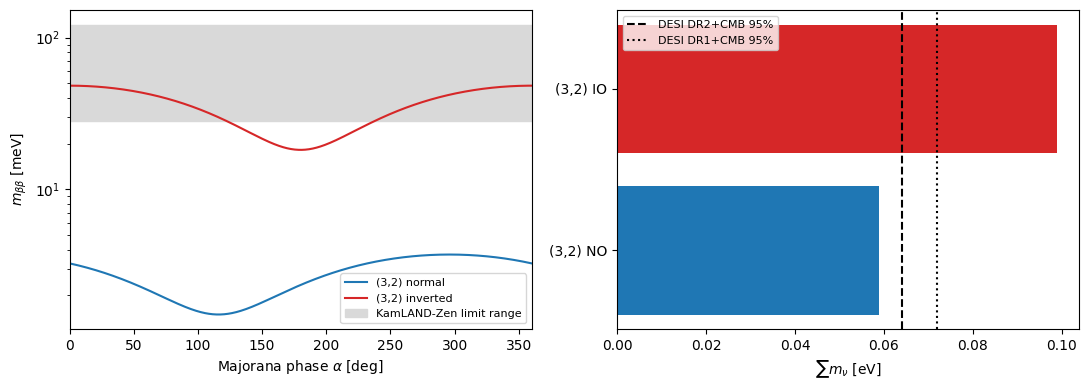

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
for ordering, color in (('normal', 'C0'), ('inverted', 'C3')):
    r = mbb['with_sk', ordering]
    ax.plot(np.degrees(r['alpha']), 1e3 * r['m_betabeta'], color=color, label=f'(3,2) {ordering}')
ax.axhspan(28, 122, color='0.85', label='KamLAND-Zen limit range')
ax.set_xlabel(r'Majorana phase $\alpha$ [deg]'); ax.set_ylabel(r'$m_{\beta\beta}$ [meV]')
ax.set_yscale('log'); ax.set_xlim(0, 360); ax.legend(fontsize=8)

ax = axes[1]
sums = {o: minimal_model(o, variants['with_sk'])['observables']['sum_masses'] for o in ('normal', 'inverted')}
ax.barh(['(3,2) NO', '(3,2) IO'], [sums['normal'], sums['inverted']], color=['C0', 'C3'])
ax.axvline(0.064, color='k', ls='--', label=r'DESI DR2+CMB 95%')
ax.axvline(0.072, color='k', ls=':', label=r'DESI DR1+CMB 95%')
ax.set_xlabel(r'$\sum m_\nu$ [eV]'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Active–sterile mixing and non-unitarity

For real $z$ the mixing is $|\Theta|^2\sim m_\nu/M_N$, unobservably small. A large $\mathrm{Im}\,z$ enhances it as $\cosh(2\,\mathrm{Im}\,z)$ at fixed light masses, which requires a cancellation in $m_D M_R^{-1}m_D^T$. The plot shows $\max|\eta_{\alpha\beta}|$, with $\eta=(1-NN^\dagger)/2$, for a low-scale realization $M_{1,2}=(1,2)$ TeV, compared with the global bound $|\eta_{\alpha\beta}|\lesssim10^{-3}$ (e.g. Blennow *et al.*, arXiv:2306.01040). The data on oscillations do not constrain $z$, but the non-unitarity bound limits $\mathrm{Im}\,z$.

normal max chi2 along the scan = 1.9181819601524335e-26
inverted max chi2 along the scan = 1.849373051249934e-26


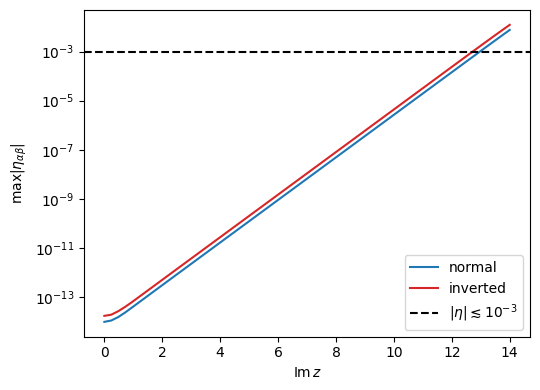

In [9]:
ys = np.linspace(0, 14, 60)
fig, ax = plt.subplots(figsize=(5.5, 4))
for ordering, color in (('normal', 'C0'), ('inverted', 'C3')):
    etas, chis = [], []
    for y in ys:
        model = minimal_model(ordering, variants['with_sk'], z=0.3 + 1j * y, heavy_masses_gev=(1e3, 2e3))
        etas.append(np.max(np.abs(model['observables']['eta'])))
        chis.append(chi2(model['observables'], variants['with_sk'], ordering))
    ax.semilogy(ys, etas, color=color, label=ordering)
    print(ordering, 'max chi2 along the scan =', max(chis))
ax.axhline(1e-3, color='k', ls='--', label=r'$|\eta|\lesssim10^{-3}$')
ax.set_xlabel(r'$\mathrm{Im}\,z$'); ax.set_ylabel(r'$\max|\eta_{\alpha\beta}|$'); ax.legend()
plt.tight_layout(); plt.show()

## 7. Conclusions

* **Active neutrinos:** $n=3$, fixed by the $Z$ width and by three non-zero mixing angles.
* **Sterile neutrinos:** $m=2$ is the minimum. With $m=1$ the light mass matrix has rank 1, two states are exactly massless, and $\Delta m^2_{21}=0$. This gives $\chi^2_{\min}\approx1.6\times10^3$ (NO) and $\gtrsim10^4$ (IO), excluded. $m=2$ and $m=3$ fit the NuFIT 6.0 best fit exactly in both orderings, with and without SK-atm.
* **The minimal model $(3,2)$** predicts $m_{\rm lightest}=0$, one Majorana phase, $\sum m_\nu\simeq0.059$ eV (NO) or $\simeq0.099$ eV (IO), and $m_{\beta\beta}\simeq1.5$–$3.7$ meV (NO) or $\simeq18$–$48$ meV (IO).
  * NO is compatible with every constraint. It is also the ordering preferred by NuFIT with SK-atm.
  * IO is in tension with DESI + CMB ($\sum m_\nu<0.064$ eV), and the upper part of its $m_{\beta\beta}$ band reaches the KamLAND-Zen limits.
* **Caveats:**
  * Loop corrections give the massless state a tiny mass (two-loop, $\ll10^{-10}$ eV), which is irrelevant here.
  * The Gaussian $\chi^2$ is an approximation to the NuFIT profiles. Exact $\Delta\chi^2$ tables would change the numbers but not the exclusion of $(3,1)$.
  * The cosmological bound depends on the model.
* **Connection to the series:** $(3,2)$ has four massive states, the largest number for which `direct_diagonalization` exists. The minimal realistic Type I seesaw is therefore exactly diagonalizable in radicals.